<h1>Import libraries</h1>

In [1]:
import requests
from bs4 import BeautifulSoup
import pandas as pd
from names_dataset import NameDataset
import matplotlib.pyplot as plt
import numpy as np
from pathlib import Path

<h1>Set parameters</h1>

In [2]:
STARTING_SERIES = 2
ENDING_SERIES = 17

<h1>Parse tables from onequestionshootout.xyz</h1>

In [3]:
headers = [
    "Date",
    "Player No.",
    "Name",
    "Cash Builder",
    "Chaser",
    "Lower Offer",
    "Higher Offer",
    "Chosen Offer",
    "HTH Result",
    "FC Correct Answers",
    "FC Winner",
    "Amount Won By Player",
    "bgc",
    "series"
]

data_raw = pd.DataFrame(columns=headers)

request_headers = {
    "User-Agent": "Mozilla/5.0"
}

for series in range(STARTING_SERIES, ENDING_SERIES+1):

    url = f"https://onequestionshootout.xyz/players/series_{series}.htm"
    response = requests.get(url, headers=request_headers)
    response.raise_for_status()

    soup = BeautifulSoup(response.text, "html.parser")

    table = soup.find("table", class_="ep")

    for tr in table.find("tbody").find_all("tr"):
        cells = tr.find_all("td")
    
        if cells:
            row = [
                cell.get_text(" ", strip=True)
                for cell in cells
            ]

        row.append(series)

        data_raw.loc[len(data_raw)] = row

<h1>View raw data</h1>

In [4]:
data_raw.head()

,Date,Player No.,Name,Cash Builder,Chaser,Lower Offer,Higher Offer,Chosen Offer,HTH Result,FC Correct Answers,FC Winner,Amount Won By Player,bgc,series
0,24/05/2010,P1,Matthew,"£9,000",Shaun Wallace,"£4,000","£20,000","£9,000 =",Home +4,6 (team 3),Chaser by 0:17,£0,C,2
1,24/05/2010,P2,Angela,"£7,000",Shaun Wallace,"£2,000","£20,000","£2,000 \/",Home +3,5 (team 3),Chaser by 0:17,£0,C,2
2,24/05/2010,P3,Les,"£14,000",Shaun Wallace,"£1,000","£29,000","£14,000 =",Caught -3,,Chaser by 0:17,£0,,2
3,24/05/2010,P4,Rebecca,"£5,000",Shaun Wallace,£100,"£22,000","£5,000 =",Home +1,5 (team 3),Chaser by 0:17,£0,C,2
4,25/05/2010,P1,Roger,"£9,000",Mark Labbett,"£4,000","£14,000","£9,000 =",Home +2,5 (team 4),Chaser by 0:10,£0,C,2


<h1>Save raw data as .csv</h1>

In [5]:
out_path = Path(f"{Path.cwd().parent}/data/raw/player_results_raw.csv")
data_raw.to_csv(out_path, index=False)
print("Saved to:", out_path.resolve())

Saved to: /Users/ben/Documents/The Chase/data/raw/player_results_raw.csv


<h1>Data cleanup</h1>

<h2>Mapping raw data columns to the new, clean dataframe.</h2>

In [6]:
data_clean = data_raw
data_clean = data_clean.rename(
    columns={
        "Date": "episode_date",
        "Player No.": "player_number",
        "Name": "player_name",
        "Chaser": "chaser_name",
        "Lower Offer": "low_offer_nominal",
        "Cash Builder": "middle_offer_nominal",
        "Higher Offer": "high_offer_nominal",
        "Chosen Offer": "s",
        "HTH Result": "m",
        "FC Correct Answers": "fc_correct_answers"
    }
)

<h2>Converting pounds strings to numeric</h2>

In [7]:
nominal_offer_column_names = ['low_offer_nominal', "middle_offer_nominal", "high_offer_nominal"]
sorted(pd.unique(data_clean[nominal_offer_column_names].values.ravel('K')))

['-£1',
 '-£1,000',
 '-£1,100',
 '-£1,497',
 '-£1,500',
 '-£1,997',
 '-£10,000',
 '-£100',
 '-£11,000',
 '-£12,000',
 '-£13,000',
 '-£14,000',
 '-£15,000',
 '-£16,000',
 '-£17,000',
 '-£2,000',
 '-£2,100',
 '-£2,200',
 '-£2,300',
 '-£2,500',
 '-£200',
 '-£3,000',
 '-£3,999',
 '-£300',
 '-£4,000',
 '-£400',
 '-£5,000',
 '-£500',
 '-£597',
 '-£6,000',
 '-£7,000',
 '-£8,000',
 '-£800',
 '-£9,000',
 '-£99',
 '-£999',
 '1p',
 '2p',
 'no offer',
 '£0',
 '£1',
 '£1,000',
 '£1,200',
 '£1,500',
 '£1,598',
 '£1,881',
 '£10',
 '£10,000',
 '£100',
 '£100,000',
 '£101,000',
 '£102,000',
 '£105,000',
 '£106,000',
 '£107',
 '£108,000',
 '£109,000',
 '£11',
 '£11,000',
 '£110,000',
 '£111,000',
 '£112,000',
 '£113,200',
 '£114,000',
 '£115,000',
 '£118,000',
 '£12,000',
 '£120,000',
 '£124,000',
 '£125',
 '£13,000',
 '£14,000',
 '£147',
 '£15,000',
 '£150',
 '£150,000',
 '£16,000',
 '£17,000',
 '£18,000',
 '£180',
 '£19',
 '£19,000',
 '£19.99',
 '£2',
 '£2,000',
 '£2,012',
 '£2,500',
 '£20',
 '£20,000

In [8]:
for offer in nominal_offer_column_names:
    # Remove pound signs
    data_clean[offer] = data_clean[offer].str.replace("£", '', regex=True)
    # Remove commas
    data_clean[offer] = data_clean[offer].str.replace(",", '', regex=True)
    # Convert 'p' to numeric
    data_clean[offer] = data_clean[offer].str.replace("1p", '0.01', regex=True)
    data_clean[offer] = data_clean[offer].str.replace("2p", '0.02', regex=True)
    # Convert 'no offer' to NaN
    data_clean[offer] = data_clean[offer].replace("no offer", np.nan, regex=True)
    # Convert to numeric type
    data_clean[offer] = pd.to_numeric(data_clean[offer])

<h2>Converting offers to s</h2>

In [9]:
data_clean.loc[data_clean["s"].str.contains(r"\/", regex=False, na=False), "s"] = "1"
data_clean.loc[data_clean["s"].str.contains("=", na=False), "s"] = "0"
data_clean.loc[data_clean["s"].str.contains("/\\", regex=False, na=False), "s"] = "-1"
data_clean["s"] = pd.to_numeric(data_clean["s"])

<h2>Converting HTH result to numeric margin</h2>

In [10]:
data_clean["m"] = data_clean["m"].str.replace("Home +", '', regex=True)
data_clean["m"] = data_clean["m"].str.replace("Caught ", '', regex=True)
data_clean["m"] = pd.to_numeric(data_clean["m"])

<h2>Converting date to datetime</h2>

In [11]:
data_clean = data_clean[~data_clean['episode_date'].str.contains('-')]

In [12]:
data_clean['episode_date'] = pd.to_datetime(data_clean['episode_date'], format="%d/%m/%Y")

<h2>Cleaning player number</h2>

In [13]:
data_clean["player_number"] = data_clean["player_number"].replace("P", "", regex=True).astype(int)

<h2>Setting dummy variable for player winning their head-to-head</h2>

In [14]:
data_clean["won_hth"] = 0
data_clean["won_hth"] = np.where(data_clean["m"] < 0, 0, 1)

<h2>Setting total banked amount</h2>

In [15]:
data_clean["money_banked_nominal"] = 0

low_mask = (data_clean["s"] == 1) & (data_clean["m"] > 0)
middle_mask = (data_clean["s"] == 0) & (data_clean["m"] > 0)
high_mask = (data_clean["s"] == -1) & (data_clean["m"] > 0)

data_clean.loc[low_mask, "money_banked_nominal"] = data_clean.loc[low_mask, "low_offer_nominal"]
data_clean.loc[middle_mask, "money_banked_nominal"] = data_clean.loc[middle_mask, "middle_offer_nominal"]
data_clean.loc[high_mask, "money_banked_nominal"] = data_clean.loc[high_mask, "high_offer_nominal"]

data_clean["total_bank_nominal"] = data_clean.groupby("episode_date")["money_banked_nominal"].cumsum().sub(data_clean["money_banked_nominal"])

<h2>Converting nominal amounts to real amounts</h2>

<h3>Downloading CPI data from Office of National Statistics</h3>

In [16]:
cpi_url = "https://www.ons.gov.uk/generator?format=csv&uri=/economy/inflationandpriceindices/timeseries/d7bt/mm23"

response = requests.get(cpi_url)
response.raise_for_status()

with open(f"{Path.cwd().parent}/data/raw/cpi_data_raw.csv", "wb") as f:
    f.write(response.content)

<h3>Cleaning the data</h3>

In [17]:
cpi_data = pd.read_csv(f"{Path.cwd().parent}/data/raw/cpi_data_raw.csv")
cpi_data = cpi_data.rename(columns={"Title": "month", "CPI INDEX 00: ALL ITEMS 2015=100": "cpi"})
cpi_data = cpi_data[cpi_data["month"].str.match(r"^\d{4} [A-Z]{3}$", na=False)]
cpi_data['month'] = pd.to_datetime(cpi_data['month'], format="%Y %b")

<h3>Setting datetimes to periods</h3>

In [18]:
cpi_data["month"] = cpi_data["month"].dt.to_period("M")
data_clean["month"] = data_clean["episode_date"].dt.to_period("M")

<h3>Joining CPI data to the clean dataframe</h3>

In [19]:
data_clean = data_clean.merge(cpi_data, on="month", how="left")

<h3>Drop observations which don't have a CPI and set to numeric</h3>

In [20]:
data_clean = data_clean.dropna(subset=["cpi"])
data_clean["cpi"] = pd.to_numeric(data_clean["cpi"])

<h3>Convert nominal GBP to real GBP amounts</h3>

In [21]:
data_clean["low_offer_real"] = round(data_clean["low_offer_nominal"] * (100 / data_clean["cpi"]),2)
data_clean["middle_offer_real"] = round(data_clean["middle_offer_nominal"] * (100 / data_clean["cpi"]), 2)
data_clean["high_offer_real"] = round(data_clean["high_offer_nominal"] * (100 / data_clean["cpi"]), 2)
data_clean["money_banked_real"] = round(data_clean["money_banked_nominal"] * (100 / data_clean["cpi"]), 2)
data_clean["total_bank_real"] = round(data_clean["total_bank_nominal"] * (100 / data_clean["cpi"]), 2)

In [22]:
data_clean.head()

,episode_date,player_number,player_name,middle_offer_nominal,chaser_name,low_offer_nominal,high_offer_nominal,s,m,fc_correct_answers,...,won_hth,money_banked_nominal,total_bank_nominal,month,cpi,low_offer_real,middle_offer_real,high_offer_real,money_banked_real,total_bank_real
0,2010-05-24,1,Matthew,9000,Shaun Wallace,4000.0,20000,0,4,6 (team 3),...,1,9000,0,2010-05,89.4,4474.27,10067.11,22371.36,10067.11,0.00
1,2010-05-24,2,Angela,7000,Shaun Wallace,2000.0,20000,1,3,5 (team 3),...,1,2000,9000,2010-05,89.4,2237.14,7829.98,22371.36,2237.14,10067.11
2,2010-05-24,3,Les,14000,Shaun Wallace,1000.0,29000,0,-3,,...,0,0,11000,2010-05,89.4,1118.57,15659.96,32438.48,0.00,12304.25
3,2010-05-24,4,Rebecca,5000,Shaun Wallace,100.0,22000,0,1,5 (team 3),...,1,5000,11000,2010-05,89.4,111.86,5592.84,24608.50,5592.84,12304.25
4,2010-05-25,1,Roger,9000,Mark Labbett,4000.0,14000,0,2,5 (team 4),...,1,9000,0,2010-05,89.4,4474.27,10067.11,15659.96,10067.11,0.00


<h2>Cleaning final chase correct answers</h2>

In [23]:
data_clean["fc_correct_answers"] = (
    data_clean["fc_correct_answers"]
    .str.replace(r"\(.*?\)", "", regex=True)
    .str.strip()
)

data_clean["fc_correct_answers"] = data_clean["fc_correct_answers"].replace("", 0, regex=True)

# Convert to numeric type
data_clean["fc_correct_answers"] = pd.to_numeric(data_clean["fc_correct_answers"])

<h2>Cleaning final chase winner</h2>

In [24]:
data_clean["fc_team_win"] = data_clean["FC Winner"].str.contains("Team", na=False).astype(int)
data_clean = data_clean.drop(columns=["FC Winner"])

In [25]:
data_clean.head()

,episode_date,player_number,player_name,middle_offer_nominal,chaser_name,low_offer_nominal,high_offer_nominal,s,m,fc_correct_answers,...,money_banked_nominal,total_bank_nominal,month,cpi,low_offer_real,middle_offer_real,high_offer_real,money_banked_real,total_bank_real,fc_team_win
0,2010-05-24,1,Matthew,9000,Shaun Wallace,4000.0,20000,0,4,6,...,9000,0,2010-05,89.4,4474.27,10067.11,22371.36,10067.11,0.00,0
1,2010-05-24,2,Angela,7000,Shaun Wallace,2000.0,20000,1,3,5,...,2000,9000,2010-05,89.4,2237.14,7829.98,22371.36,2237.14,10067.11,0
2,2010-05-24,3,Les,14000,Shaun Wallace,1000.0,29000,0,-3,0,...,0,11000,2010-05,89.4,1118.57,15659.96,32438.48,0.00,12304.25,0
3,2010-05-24,4,Rebecca,5000,Shaun Wallace,100.0,22000,0,1,5,...,5000,11000,2010-05,89.4,111.86,5592.84,24608.50,5592.84,12304.25,0
4,2010-05-25,1,Roger,9000,Mark Labbett,4000.0,14000,0,2,5,...,9000,0,2010-05,89.4,4474.27,10067.11,15659.96,10067.11,0.00,0


<h2>Adding gender</h2>

In [26]:
nd = NameDataset()

In [27]:
def get_male_first_name_prob(name):
    
    search_result = nd.search(name)
    first_name_result = search_result['first_name']

    if search_result['first_name'] is None:
        return np.nan
        
    if 'Male' in first_name_result['gender'].keys(): 
        return first_name_result['gender']['Male']
    else:
        return 1

In [28]:
data_clean["male_name"] = data_clean["player_name"].apply(get_male_first_name_prob)

In [29]:
data_clean.head()

,episode_date,player_number,player_name,middle_offer_nominal,chaser_name,low_offer_nominal,high_offer_nominal,s,m,fc_correct_answers,...,total_bank_nominal,month,cpi,low_offer_real,middle_offer_real,high_offer_real,money_banked_real,total_bank_real,fc_team_win,male_name
0,2010-05-24,1,Matthew,9000,Shaun Wallace,4000.0,20000,0,4,6,...,0,2010-05,89.4,4474.27,10067.11,22371.36,10067.11,0.00,0,0.993
1,2010-05-24,2,Angela,7000,Shaun Wallace,2000.0,20000,1,3,5,...,9000,2010-05,89.4,2237.14,7829.98,22371.36,2237.14,10067.11,0,0.008
2,2010-05-24,3,Les,14000,Shaun Wallace,1000.0,29000,0,-3,0,...,11000,2010-05,89.4,1118.57,15659.96,32438.48,0.00,12304.25,0,0.805
3,2010-05-24,4,Rebecca,5000,Shaun Wallace,100.0,22000,0,1,5,...,11000,2010-05,89.4,111.86,5592.84,24608.50,5592.84,12304.25,0,0.007
4,2010-05-25,1,Roger,9000,Mark Labbett,4000.0,14000,0,2,5,...,0,2010-05,89.4,4474.27,10067.11,15659.96,10067.11,0.00,0,0.991


(array([3776.,  246.,  127.,   93.,  136.,   68.,  116.,  161.,  276.,
        4364.]),
 array([0.002 , 0.1018, 0.2016, 0.3014, 0.4012, 0.501 , 0.6008, 0.7006,
        0.8004, 0.9002, 1.    ]),
 <BarContainer object of 10 artists>)

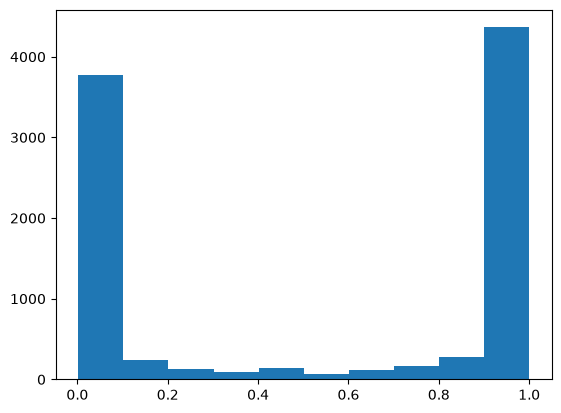

In [30]:
plt.hist(data_clean['male_name'])

<h1>Save results</h1>

In [31]:
out_path = Path(f"{Path.cwd().parent}/data/processed/player_results.csv")
data_clean.to_csv(out_path, index=False)
print("Saved to:", out_path.resolve())  # shows the full path it was saved to

Saved to: /Users/ben/Documents/The Chase/data/processed/player_results.csv
